# Where is a loaded steel part strained?

You are operating the ODIN imaging instrument at ESS. Behind this page, a simulation of the instrument produces your
measurements; the files are in the ESS NeXus format, and the wavelength of each neutron is computed with the official
ESS software.

**Your mission.** You are an engineer in a team that designs steel parts for a wind turbine. A part carries a large
force: where, inside the steel, is the material strained, and by how much? A strain gauge glued on the surface only
tells what happens at the surface. Neutrons go through the steel, and the wavelength of a **Bragg edge** is set by the
distance between planes of atoms: if the load changes this distance by one part in a thousand, the edge moves by one
part in a thousand. Your job: measure a steel specimen in a load frame, without load and under load, deduce the strain
of its crystal lattice in its narrow part and in its wide parts, and tell the team whether the steel behaves as
designed (part 6).

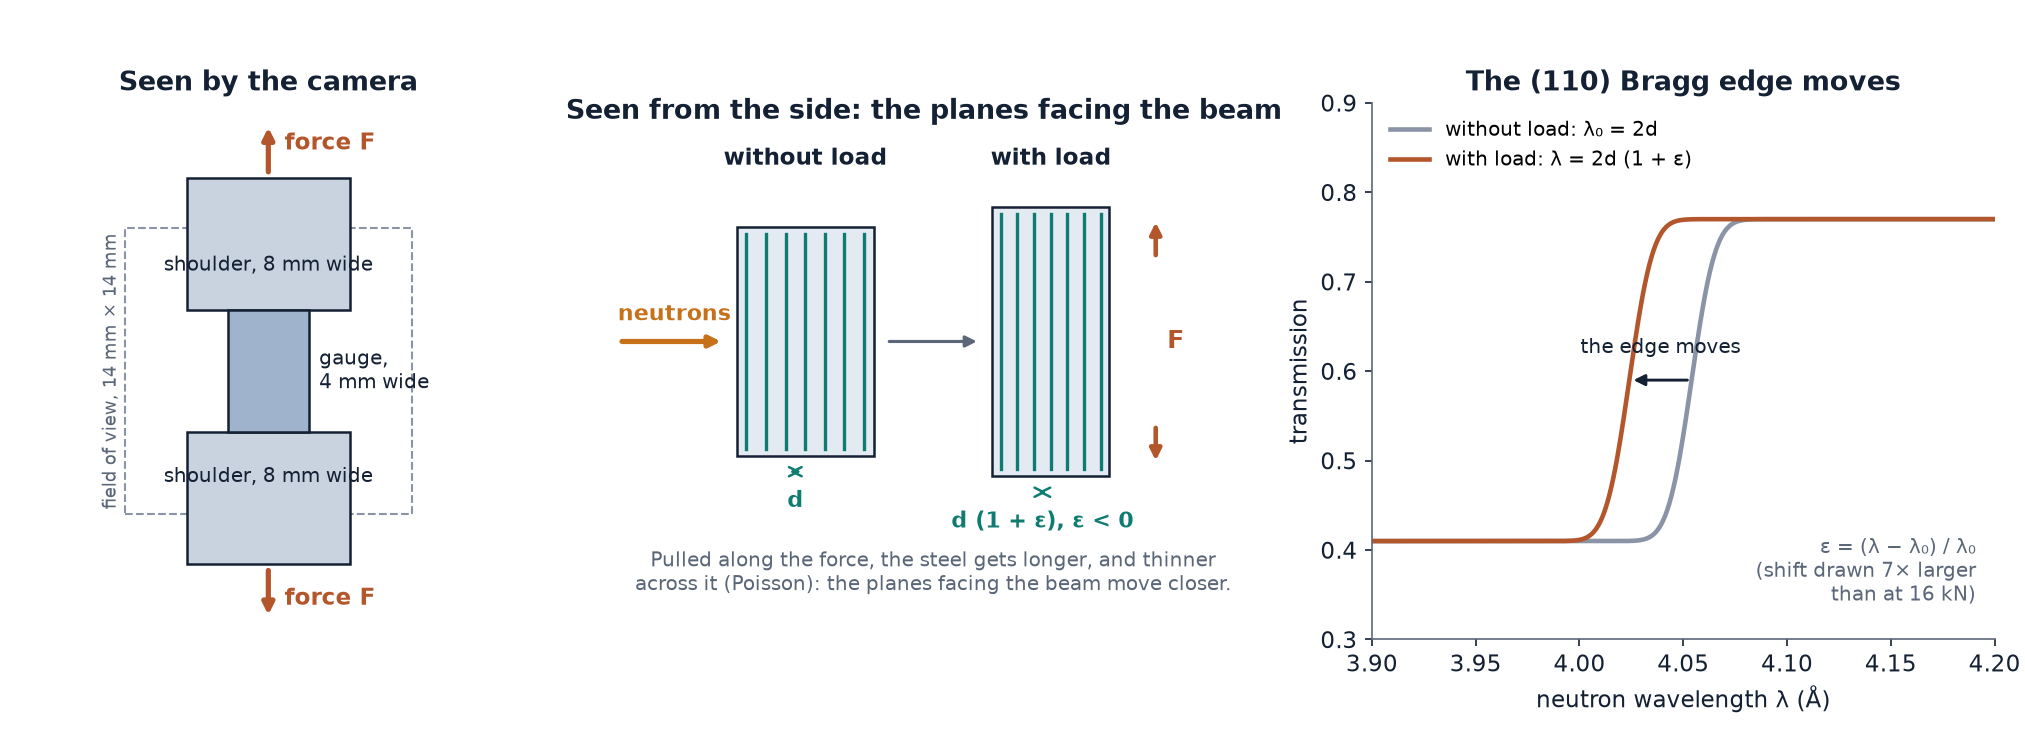

*The specimen in its load frame as the camera sees it (left); pulled along the force, the steel gets thinner across it, and the planes facing the beam move closer (middle); the Bragg edge of these planes moves to a shorter wavelength (right).*

**What you will measure.** A Bragg edge is the wavelength beyond which a family of planes can no longer scatter the
neutrons: $\lambda_\text{edge} = 2d$, with $d$ the distance between the planes. At the edge the neutrons are scattered
straight back, so the planes that count are those **facing the beam**. Under load $d$ becomes $d\,(1+\varepsilon)$,
and the edge moves from $\lambda_0$ to $\lambda$:

$$\varepsilon = \frac{\lambda - \lambda_0}{\lambda_0}$$

$\varepsilon$ is the **strain** of the lattice along the beam: a number without unit, here about $10^{-3}$.

**You need five measurements**:
1. the **dark** run: shutter closed (the background of the detector);
2. the **open beam**: shutter open, specimen moved out of the beam;
3. the specimen **without load** (0 kN): the reference, which gives $\lambda_0$;
4. the specimen at **8 kN**;
5. the specimen at **16 kN**.

In [ ]:
import sys, os, json, warnings
warnings.filterwarnings("ignore")
sys.path[:0] = [os.path.abspath("../../.."), os.path.abspath("../..")]     # twin/ and twin/odin/
import web_user
web_user.sign_in()            # the online version: the student named on the start page (nothing to do in the app)
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, clear_output
from odin_virtual import VirtualOdin
import odin_viz as viz, odin_strain as strain
import sample_library as sl
from page_output import into

SAMPLE = "steel_tensile"
odin = VirtualOdin(session=os.environ.get("ODIN_SESSION", "student"))
odin.move(sample=SAMPLE)

## 0. Your specimen

A flat **tensile specimen** of ferritic steel (α-iron), 5 mm thick, held in a load frame that pulls it along the
vertical axis with a force $F$ that you choose (up to 16 kN, the weight of 1.6 tonnes). The drawing shows it as the
neutrons see it (left: the 14 mm field of view of the camera, dashed) and from above (right: its thickness along the
beam).

The same force crosses every horizontal section of the specimen. The **stress** is the force per unit of
cross-section, $\sigma = F / A$ (in MPa = N/mm²):

| Part | Width × thickness | Cross-section $A$ | Stress at 16 kN |
|---|---|---|---|
| gauge (narrow, center) | 4 mm × 5 mm | 20 mm² | 800 MPa |
| shoulders (wide, top and bottom) | 8 mm × 5 mm | 40 mm² | 400 MPa |

The steel of the specimen stays elastic up to about 900 MPa: below, it comes back to its shape when the load is
removed, and the strain is proportional to the stress (Hooke's law), $\varepsilon_\text{load} = \sigma / E$ along the
force, with $E$ = 210 GPa for steel (Young's modulus, measured on a tensile machine).

In [ ]:
spec = odin.sample_spec(SAMPLE)
smp_out = w.Output()
with into(smp_out):
    sl.draw("odin", spec, fig=plt.figure(figsize=(10, 4)))
    sl.show()
display(smp_out)

## 1. Operate the instrument

Set the controls, then click *Count*: the detector image and the spectrum of arrival times fill up during the count,
as on the instrument. One count per row:

| Measurement | Shutter | Stage x (mm) | Load (kN) | Time (s) | Title |
|---|---|---|---|---|---|
| 1. dark | **closed** | 0 | 0 | 30 | dark |
| 2. open beam | **open** | **500** | 0 | 60 | open beam |
| 3. reference | open | **0** | **0** | 60 | steel 0 kN |
| 4. half load | open | 0 | **8** | 60 | steel 8 kN |
| 5. full load | open | 0 | **16** | 60 | steel 16 kN |

Why these settings:
- the **choppers** are in WFM mode (wavelength frame multiplication, discs 0.30 m apart) and the **pinhole** is
  3 cm wide for all the measurements: WFM cuts the long ESS pulse into short sub-pulses, which gives the sharp edges
  that a shift of $10^{-3}$ needs. The beam must be the same for all the measurements, so these settings are fixed here;
- **stage x = 500 mm** moves the specimen (with its load frame) 50 cm aside, out of the field of view: the open beam;
- the **reference at 0 kN** is measured on the specimen itself, in the same position: the strain is the *change* of
  the edge, and everything else must stay the same (question Q7);
- **60 s** per measurement give the edge position to about ± 0.0005 Å; the shift at 16 kN is about 0.005 Å.
  A count lasts as long as on the instrument: about 5 minutes in total.

In [ ]:
st = odin.status()
shut = w.ToggleButtons(options=[("closed", "closed"), ("open", "open")], value=st["shutter"], description="Shutter")
stage = w.BoundedFloatText(value=st["stage_x"] * 1000, min=-500, max=500, step=1, description="Stage x (mm)")
load = w.FloatSlider(value=st["load"], min=0, max=16, step=1, description="Load (kN)", readout_format=".0f",
                     continuous_update=False, layout=w.Layout(width="420px"))
ttime = w.Dropdown(options=[10, 30, 60, 90], value=30, description="Time (s)")
title = w.Text(value="", placeholder="e.g. steel 8 kN", description="Title")
button = w.Button(description="Count", button_style="primary", icon="play", layout=w.Layout(width="auto"))
out = w.Output()

def do_count(_):
    button.disabled = True
    with out:
        clear_output()
        try:
            odin.move(choppers="wfm", wfm_delta=0.30, pinhole=0.03, diffuser="in", shutter=shut.value,
                      stage_x=stage.value / 1000, sample=SAMPLE, load=float(load.value))
            live = viz.LiveCount()                  # the image and the spectrum fill up during the count
            f = odin.count(ttime.value, title=title.value or default_title(), progress=live.update)
            live.done(f)
        except Exception as e:
            print("Error:", e)
    button.disabled = False
    refresh_list()

def default_title():
    if shut.value == "closed":
        return "dark"
    return "open beam" if abs(stage.value) > 20 else f"steel {load.value:.0f} kN"

button.on_click(do_count)
display(w.VBox([shut, stage, load, ttime, title, button, out]))

## 2. Your measurements

Each count produces a numbered file, as on the real instrument. The table recalls the state of the instrument during
each measurement: this is your logbook.

In [ ]:
listing = w.Output()

def measurements():
    ms = []
    if os.path.isfile(odin.log_file):
        for l in open(odin.log_file, encoding="utf-8"):
            e = json.loads(l)
            if e["action"] == "count" and e["details"].get("file"):
                d = e["details"]; s = d["state"]
                kind = "dark" if s["shutter"] == "closed" else ("open beam" if abs(s["stage_x"]) > 0.02 else "specimen")
                if s.get("sample") != SAMPLE and kind == "specimen":
                    continue
                ms.append(dict(file=d["file"], path=os.path.join(odin.folder, d["file"]), title=d["title"], t=d["t"],
                               kind=kind, load=float(s.get("load") or 0), counts=d["n_counts"],
                               wfm=(s["choppers"] == "wfm" and abs(s["wfm_delta"] - 0.30) < 1e-6)))
    return [m for m in ms if m["wfm"]]

def label(m):
    return f"{m['file']}: {m['title'] or '(no title)'}" + (f" ({m['load']:g} kN)" if m["kind"] == "specimen" else "")

def refresh_list():
    ms = measurements()
    of = lambda kind, cond=lambda m: True: [(label(m), m["path"]) for m in reversed(ms) if m["kind"] == kind and cond(m)]
    for dd, opts in ((pick_L, of("specimen", lambda m: m["load"] > 0)), (pick_R, of("specimen", lambda m: m["load"] == 0)),
                     (pick_O, of("open beam")), (pick_N, of("dark"))):
        dd.options = opts                # the newest first, and chosen (a new list leaves the choice empty)
        if opts:
            dd.value = opts[0][1]
    with into(listing):
        if not ms:
            print("No measurement yet.")
        for m in ms:
            print(f"{m['file']}  {m['title'] or '(no title)':16s} {m['kind']:10s} t = {m['t']:3g} s  load = {m['load']:4g} kN"
                  f"  -> {m['counts']:,} counts")

wide = w.Layout(width="520px")
pick_L = w.Dropdown(description="Under load", layout=wide)
pick_R = w.Dropdown(description="Reference", layout=wide)
pick_O = w.Dropdown(description="Open beam", layout=wide)
pick_N = w.Dropdown(description="Dark", layout=wide)
refresh_list()
display(listing)

## 3. The edge, without and with load

For each wavelength, the transmission of a region of the specimen is

$$T = \frac{E - N}{O - N}$$

with $E$, $O$ and $N$ the counts of the specimen, open-beam and dark runs in that region (the dark is scaled to the
duration of each measurement, and each measurement is divided by the proton charge received by the target).

Choose a measurement under load, the reference, and a region; *Fit the edge* draws the two transmissions around the
last Bragg edge of iron, that of the (110) planes, near 4.05 Å. The edge is not a sharp step: the wavelength
resolution of the instrument smooths it over about 0.02 Å. Its position is found by **fitting** a smoothed step to
all the points of the edge: this is how a shift ten times smaller than the width of the edge can be measured.
The first time a file is used, reading its millions of neutrons takes about 20 s.

In [ ]:
region = w.Dropdown(options=list(strain.REGIONS), value="gauge", description="Region", layout=wide)
button_fit = w.Button(description="Fit the edge", button_style="success", icon="chart-line", layout=w.Layout(width="auto"))
out_fit = w.Output()

def chosen():
    if not (pick_L.value and pick_R.value and pick_O.value):
        raise ValueError("Measure first: an open beam, the specimen without load (0 kN) and under load (part 1).")
    return pick_L.value, pick_R.value, pick_O.value, pick_N.value

def load_of(path):
    return next(m["load"] for m in measurements() if m["path"] == path)

def fit_edge(_):
    button_fit.disabled = True
    with out_fit:
        clear_output()
        try:
            L, R, O, N = chosen()
            print("Reading the files and fitting...")
            a, b = strain.edge(L, O, N, region.value), strain.edge(R, O, N, region.value)
            e, de = strain.strain(a, b)
            kN = load_of(L)
            clear_output()
            fig, ax = plt.subplots(figsize=(8.5, 4.6))
            strain.plot_edges(ax, a, b, kN, region.value)
            plt.tight_layout(); plt.show()
            print(f"{region.value}, {kN:g} kN: stress = {strain.stress_MPa(kN, region.value):.0f} MPa")
            print(f"  edge without load: {b['lam_edge']:.4f} ± {b['dlam_edge']:.4f} Å")
            print(f"  edge under load  : {a['lam_edge']:.4f} ± {a['dlam_edge']:.4f} Å")
            print(f"  strain along the beam: ε = ({a['lam_edge']:.4f} − {b['lam_edge']:.4f}) / {b['lam_edge']:.4f} "
                  f"= ({e * 1e3:+.2f} ± {de * 1e3:.2f}) × 10⁻³")
            if N is None:
                print("Note: no dark run, the background is not subtracted.")
        except Exception as err:
            clear_output()
            print("Not possible yet:", err)
    button_fit.disabled = False

button_fit.on_click(fit_edge)
display(w.VBox([pick_L, pick_R, pick_O, pick_N, region, button_fit, out_fit]))

**Reading the result.** The edge under load is at a *shorter* wavelength: the strain along the beam is **negative**,
although the specimen is pulled. Pulled along the force, the steel gets longer, and thinner across it: this is the
Poisson effect, $\varepsilon_\text{across} = -\nu\,\varepsilon_\text{load}$, with $\nu$ (Poisson's ratio) about 0.3
for steel. The beam crosses the specimen *across* the force: the planes facing the beam move closer.

## 4. The strain map

*Map the strain* fits the edge in the three parts of the specimen, without and under load, and colors each part by
its strain along the beam.

In [ ]:
button_map = w.Button(description="Map the strain", button_style="success", icon="th", layout=w.Layout(width="auto"))
out_map = w.Output()

def strains_of(L, R, O, N):
    return {r: strain.strain(strain.edge(L, O, N, r), strain.edge(R, O, N, r)) for r in strain.REGIONS}

def do_map(_):
    button_map.disabled = True
    with out_map:
        clear_output()
        try:
            L, R, O, N = chosen()
            print("Reading the files and fitting the three regions...")
            res = strains_of(L, R, O, N)
            kN = load_of(L)
            clear_output()
            fig, ax = plt.subplots(figsize=(6.4, 5.2))
            fig.colorbar(strain.plot_map(ax, strain.transmission_image(L, O), res), ax=ax, label="strain along the beam (10⁻³)")
            ax.set_title(f"Strain along the beam at {kN:g} kN (10⁻³)")
            plt.tight_layout(); plt.show()
            for r, (e, de) in res.items():
                print(f"{r:15s} stress {strain.stress_MPa(kN, r):4.0f} MPa   strain ({e * 1e3:+.2f} ± {de * 1e3:.2f}) × 10⁻³")
        except Exception as err:
            clear_output()
            print("Not possible yet:", err)
    button_map.disabled = False

button_map.on_click(do_map)
display(w.VBox([button_map, out_map]))

**A map with three regions only?** With 60 s per measurement, a region needs several mm² to collect enough neutrons
for a shift of $10^{-3}$. Real strain maps have pixels well below a millimeter: they take hours of beam time per
load. The principle is the same.

**Limit of the twin.** Each part of the specimen has one uniform stress, $F/A$. In a real specimen the stress changes
progressively where the section changes, and is larger in the corners (stress concentration): this is not modeled.

## 5. Strain against stress

*Strain against stress* uses **all** your measurements under load (8 kN, 16 kN, and others if you made more) and
the three regions: each gives one point, the strain along the beam against the stress $\sigma = F/A$ of the region.
If the steel is elastic, all the points are on one straight line through zero, of slope $-\nu / E$.

In [ ]:
button_line = w.Button(description="Strain against stress", button_style="success", icon="chart-line", layout=w.Layout(width="auto"))
out_line = w.Output()
E_GPA = 210.0

def do_line(_):
    button_line.disabled = True
    with out_line:
        clear_output()
        try:
            _, R, O, N = chosen()
            loaded = {}
            for m in measurements():                     # the last measurement of each load
                if m["kind"] == "specimen" and m["load"] > 0:
                    loaded[m["load"]] = m["path"]
            print(f"Reading the files and fitting ({len(loaded)} loads, three regions)...")
            pts = []
            for kN, path in sorted(loaded.items()):
                for r, (e, de) in strains_of(path, R, O, N).items():
                    pts.append((strain.stress_MPa(kN, r), e, de, r, kN))
            x, y, dy = (np.array([p[k] for p in pts]) for k in range(3))
            a, da = strain.line_through_zero(x, y, dy)
            nu, dnu = -a * E_GPA * 1e3, da * E_GPA * 1e3
            clear_output()
            fig, ax = plt.subplots(figsize=(8, 4.8))
            for r, c, mk in (("gauge", "tab:red", "o"), ("upper shoulder", "tab:blue", "^"), ("lower shoulder", "tab:blue", "v")):
                k = [i for i, p in enumerate(pts) if p[3] == r]
                ax.errorbar(x[k], y[k] * 1e3, yerr=dy[k] * 1e3, fmt=mk, color=c, capsize=3, label=r)
            xs = np.array([0, max(x) * 1.08])
            ax.plot(xs, a * xs * 1e3, "k-", lw=1.2, label=f"line through zero: slope ({a * 1e6:.2f} ± {da * 1e6:.2f}) × 10⁻⁶ per MPa")
            ax.plot(0, 0, "ks", ms=5)
            ax.set(xlabel="stress σ = F / A (MPa)", ylabel="strain along the beam (10⁻³)", title="Strain against stress")
            ax.grid(alpha=0.3); ax.legend(fontsize=9)
            plt.tight_layout(); plt.show()
            print(f"slope = −ν / E = ({a * 1e6:.2f} ± {da * 1e6:.2f}) × 10⁻⁶ per MPa")
            print(f"with E = {E_GPA:.0f} GPa = {E_GPA * 1e3:.0f} MPa:  ν = −slope × E = {nu:.2f} ± {dnu:.2f}")
        except Exception as err:
            clear_output()
            print("Not possible yet:", err)
    button_line.disabled = False

button_line.on_click(do_line)
display(w.VBox([button_line, out_line]))

## 6. Questions: your verdict

Answer in the boxes, then click *Check*. A wrong answer is explained; after a try you can also show the answer.
Your answers are kept, and *My results* (at the end) gives your score and a report to download.

In [ ]:
import quiz
q = quiz.Quiz("odin_steel_bsc")
q.number("At which wavelength is the (110) edge of the specimen **without load** (part 3, gauge)?",
         value=4.056, tol=0.012, unit="Å",
         mistakes=[(2.867, "the (200) edge; the (110) edge is the last one, near 4.05 Å"),
                   (2.027, "the distance d between the planes; the edge is at λ = 2d")],
         hints=["Part 3 prints it after the fit: 'edge without load'.", "It is between 4.04 and 4.07 Å."],
         explanation="The (110) planes of α-iron are d = 2.027 Å apart, so the edge is at 2d = 4.054 Å. Your fit gives "
                     "it to about ± 0.0005 Å, a few 0.001 Å above: the shape of the neutron pulses shifts the fitted "
                     "position a little, the same way for all your measurements.", title="Q1. The edge without load")
q.choice("The transmission measurement gives the strain of the lattice in one direction only. Which one?",
         ["Along the beam: at the edge the neutrons are scattered straight back, by the planes facing the beam.",
          "Along the force: this is where the steel is stretched.",
          "The average over all directions.",
          "Along the width of the specimen (horizontal, across the beam)."],
         answer=0, why={1: "The planes that set the edge are those facing the beam (back-scattering, λ = 2d): their "
                           "distance is measured along the beam, not along the force.",
                        2: "At the edge only one orientation of the planes scatters: the one facing the beam.",
                        3: "The planes that set the edge face the beam: their distance is measured along the beam."},
         explanation="λ_edge = 2d is Bragg's law for θ = 90°: back-scattering by the planes perpendicular to the beam. "
                     "The edge gives their distance, so the strain along the beam. To get the strain along the force, "
                     "the specimen would have to be turned (or measured by diffraction).",
         hints=["Bragg's law λ = 2d sin θ: which θ gives the largest λ, the edge?",
                "θ = 90°: the neutron comes straight back. How are the planes oriented with respect to the beam?"],
         title="Q2. Which strain?")
q.number("What is the stress in the gauge (4 mm × 5 mm) at 16 kN?", value=800, tol=10, unit="MPa",
         mistakes=[(400, "the stress in the shoulders (40 mm²); the gauge has 20 mm²"),
                   (0.8, "in GPa (or kN/mm²); the answer is asked in MPa = N/mm²"),
                   (320, "you multiplied; stress = force / cross-section")],
         hints=["Stress = force / cross-section, with the force in N and the section in mm² to get MPa.",
                "16 kN = 16 000 N; the section is 4 mm × 5 mm = 20 mm²."],
         explanation="σ = F/A = 16 000 N / 20 mm² = 800 MPa, below the elastic limit of this steel (about 900 MPa).",
         title="Q3. The stress in the gauge")
q.number("With E = 210 GPa, which strain **along the force** does Hooke's law give in the gauge at 16 kN? "
         "(in units of 10⁻³)", value=3.81, tol=0.08, unit="× 10⁻³",
         mistakes=[(0.00381, "right, but the answer is asked in units of 10⁻³: 3.81"),
                   (1.90, "the shoulders (400 MPa); the gauge is at 800 MPa"),
                   (-1.10, "the strain along the beam; along the force it is σ/E, positive")],
         hints=["ε = σ / E, with σ and E in the same unit.", "σ = 800 MPa and E = 210 000 MPa."],
         explanation="ε = σ/E = 800 / 210 000 = 3.81 × 10⁻³: the gauge (6 mm) gets 0.023 mm longer.",
         title="Q4. Hooke's law")
q.number("Which strain **along the beam** did you measure in the gauge at 16 kN (part 3 or 4)? (in units of 10⁻³, "
         "with its sign)", value=-1.10, tol=0.45, unit="× 10⁻³",
         mistakes=[(1.10, "the sign: the edge moved to a shorter wavelength, so the strain is negative"),
                   (-0.55, "the shoulders; the gauge is strained twice as much"),
                   (3.81, "the strain along the force (Q4); the measurement gives the strain along the beam")],
         hints=["Part 3 prints it for the gauge with the run at 16 kN.", "It is negative, about −1 × 10⁻³."],
         explanation="The expected value is −ν σ/E = −0.29 × 3.81 × 10⁻³ = −1.10 × 10⁻³. With 60 s per measurement your "
                     "value has an uncertainty of about ± 0.2 × 10⁻³: yours is right if it agrees within about twice "
                     "this uncertainty.", title="Q5. Your measurement")
q.number("Which Poisson's ratio ν do your measurements give (part 5)?", value=0.29, tol=0.09,
         mistakes=[(-0.29, "the sign: ν = −slope × E is positive"), (3.4, "ν = −ε_beam / ε_load, not the inverse")],
         hints=["Part 5 prints it: ν = −slope × E.", "For steel it is close to 0.3."],
         explanation="ν = −ε_across / ε_load: about 0.29 for ferritic steel. The steel gets thinner by 0.29 times what "
                     "it gains in length (in relative value).", title="Q6. Poisson's ratio")
q.choice("Why measure the specimen **without load** rather than use the textbook value of the edge, 4.054 Å?",
         ["The strain is a difference of 10⁻³: the alloy and the instrument shift the edge by as much, the same way in "
          "both measurements, so the difference removes it.",
          "The textbook value is for 0 K.",
          "To subtract the background of the detector.",
          "It is not needed: the textbook value would give the same strain."],
         answer=0, why={1: "Thermal expansion matters, but it is one of several shifts; what removes them all?",
                        2: "The background is removed by the dark run.",
                        3: "Look at Q1: your edge without load is already a few 0.001 Å away from 4.054 Å, as much as "
                           "the shift you are looking for."},
         explanation="The edge of your unloaded specimen is not exactly at 4.054 Å: the alloying elements of a steel "
                     "change its lattice parameter, and the shape of the neutron pulses shifts the fitted position. "
                     "These shifts are as large as the strain, but identical with and without load: the difference "
                     "removes them. Finding a reliable reference is the main difficulty of real strain measurements.",
         hints=["Compare your edge without load (Q1) with 4.054 Å: how large is the difference, compared with the "
                "shift under load?", "What stays the same between the measurement without load and under load?"],
         title="Q7. The reference")
q.choice("The edge is about 0.02 Å wide and moves by 0.005 Å. How can such a small shift be measured?",
         ["A smoothed step is fitted to all the points of the edge: its position is known far better than its "
          "width, the better the more neutrons are counted.",
          "It cannot: a shift smaller than the width is not measurable.",
          "By using wavelength bins of 0.0001 Å.",
          "By reading the highest point of the edge."],
         answer=0, why={1: "You have just done it: look at the uncertainties of part 3.",
                        2: "Narrower bins hold fewer neutrons each: the noise grows, the information is the same.",
                        3: "A single point is noisy; the fit uses all of them."},
         explanation="The position of a known shape is found with a precision of about its width divided by the "
                     "square root of the number of neutrons that draw it. With millions of neutrons, 0.0005 Å for an "
                     "edge 0.02 Å wide.",
         hints=["How many points of the spectrum does the fit use?",
                "The mean of N values is known √N times better than one value."],
         title="Q8. Smaller than the resolution")
q.choice("You want error bars on the strain **twice** smaller. How long should each measurement be?",
         ["240 s (4 times longer)", "120 s (twice longer)", "90 s", "30 s, with narrower wavelength bins"],
         answer=0, why={1: "Twice the neutrons give errors √2 = 1.4 times smaller, not 2.",
                        2: "1.5 times the neutrons give errors 1.2 times smaller.",
                        3: "Fewer neutrons: larger error bars."},
         explanation="Counting statistics: the uncertainty goes as 1/√N. Twice smaller needs 4 times the neutrons, so "
                     "4 times the time. This is why real strain maps take hours.",
         hints=["N counts have an uncertainty √N.", "1/√N twice smaller: N how many times larger?"],
         title="Q9. Counting time")
q.choice("**Your verdict for the team.** What do your measurements show?",
         ["The steel is elastic up to 800 MPa: the strain is proportional to the stress, twice as large in the gauge "
          "as in the shoulders, with ν ≈ 0.3 as expected for steel.",
          "The gauge has yielded: its strain is twice that of the shoulders.",
          "The strain is the same everywhere: the force is the same in every section.",
          "Nothing: the shifts are within the error bars."],
         answer=0, why={1: "Twice the strain is what elasticity predicts for half the cross-section (twice the stress); "
                           "yielding would put the gauge *off* the line of part 5.",
                        2: "The force is the same, but not the stress: the gauge has half the cross-section.",
                        3: "At 16 kN the shift of the gauge is about 6 times its uncertainty."},
         explanation="All the points of part 5 are on one line through zero: the same law σ → ε holds in the gauge and "
                     "in the shoulders, the signature of elastic behavior. The slope gives ν/E as expected for steel: "
                     "the part behaves as designed.",
         hints=["Look at part 5: are the points of the gauge and of the shoulders on the same line?",
                "Same force, half the cross-section: how do the stresses compare?"],
         title="Q10. The verdict")
q.report()

## 7. Submit your work

When you are done, submit: the file for your teacher is made from your answers and your measurements.

In [ ]:
import submit
_ = submit.Submit("odin/exercises/steel_strain", "bsc", quiz=q)